In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv")

In [3]:
df.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# Operaciones fila

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
# Expresiones regulares
df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)

<>:2: SyntaxWarning: invalid escape sequence '\.'
<>:2: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_4678/965365120.py:2: SyntaxWarning: invalid escape sequence '\.'
  df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df["free_ticket"] = df["Fare"] == 0.0

In [8]:
df["family_size"] = df["SibSp"] + df["Parch"] + 1

In [9]:
df["is_alone"] = df["family_size"] == 1

In [10]:
df.isna().sum()[df.isna().sum() > 0] / df.shape[0] * 100

,0
Age,19.865320
Cabin,77.104377
Embarked,0.224467


In [11]:
del df["Cabin"]

In [12]:
del df["PassengerId"]

In [13]:
del df["Name"]

In [14]:
del df["Ticket"]

In [15]:
df.head(5)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,free_ticket,family_size,is_alone
0,0,3,male,22.0,1,0,7.2500,S,Mr,False,2,False
1,1,1,female,38.0,1,0,71.2833,C,Mrs,False,2,False
2,1,3,female,26.0,0,0,7.9250,S,Miss,False,1,True
3,1,1,female,35.0,1,0,53.1000,S,Mrs,False,2,False
4,0,3,male,35.0,0,0,8.0500,S,Mr,False,1,True


# Operaciones con información global

In [16]:
X = df.drop("Survived", axis = 1)
y = df["Survived"]

In [17]:
y.value_counts() / df.shape[0] * 100

,count
Survived,
0,61.616162
1,38.383838


In [18]:
from sklearn.model_selection import train_test_split

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify = y
)

In [20]:
X_train = X_train.reset_index(drop = True)
X_test = X_test.reset_index(drop = True)

In [21]:
y_train.value_counts() / X_train.shape[0] * 100

,count
Survived,
0,61.637239
1,38.362761


In [22]:
y_test.value_counts() / X_test.shape[0] * 100

,count
Survived,
0,61.567164
1,38.432836


In [23]:
mode_embarked = X_train["Embarked"].mode().iloc[0]
X_train["Embarked"] = X_train["Embarked"].fillna(mode_embarked)
X_test["Embarked"] = X_test["Embarked"].fillna(mode_embarked)

In [24]:
from sklearn.preprocessing import OneHotEncoder

In [25]:
for column in ["Title", "Embarked", "Sex"]:
    encoder = OneHotEncoder(sparse_output=False, handle_unknown = "ignore")
    encoder.fit(X_train[[column]])
    X_train = pd.concat([
        X_train.drop(column, axis = 1),
        pd.DataFrame(
            encoder.transform(X_train[[column]]),
            columns = map(lambda x: column + "_" + str(x), encoder.categories_[0])
        )],
        axis = 1
    )
    X_test = pd.concat([
        X_test.drop(column, axis = 1),
        pd.DataFrame(
            encoder.transform(X_test[[column]]),
            columns = map(lambda x: column + "_" + str(x), encoder.categories_[0])
        )],
        axis = 1
    )

In [26]:
age_mean = X_train["Age"].mean()
X_train["Age"] = X_train["Age"].fillna(age_mean)
X_test["Age"] = X_test["Age"].fillna(age_mean)

In [27]:
X_train

,Pclass,Age,SibSp,Parch,Fare,free_ticket,family_size,is_alone,Title_Col,Title_Don,...,Title_Mlle,Title_Mr,Title_Mrs,Title_Rev,Title_Sir,Embarked_C,Embarked_Q,Embarked_S,Sex_female,Sex_male
0,1,19.000000,1,0,53.1000,False,2,False,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1,3,30.045476,0,0,8.0500,False,1,True,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2,3,30.045476,0,0,7.8792,False,1,True,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3,1,30.045476,0,0,0.0000,True,1,True,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
4,3,28.000000,1,0,15.8500,False,2,False,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
618,2,34.000000,1,0,21.0000,False,2,False,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
619,2,32.000000,0,0,13.0000,False,1,True,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
620,3,48.000000,1,3,34.3750,False,5,False,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
621,1,47.000000,0,0,38.5000,False,1,True,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0


In [28]:
from sklearn.preprocessing import StandardScaler

In [29]:
numeric_val = X_train[["Age", "SibSp", "Parch", "Fare", "family_size", "Pclass"]]
scaler = StandardScaler()
scaler.fit(numeric_val)

StandardScaler()

In [30]:
X_train[["Age", "SibSp", "Parch", "Fare", "family_size", "Pclass"]] = scaler.transform(numeric_val)
X_test[["Age", "SibSp", "Parch", "Fare", "family_size", "Pclass"]] = scaler.transform(X_test[["Age", "SibSp", "Parch", "Fare", "family_size", "Pclass"]])

In [31]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(units = 1, activation = "sigmoid")
])


model.compile(
    optimizer = "adam",
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=[tf.keras.metrics.F1Score(threshold=0.5)]
)

In [32]:
model.fit(X_train, y_train, epochs = 200)

Epoch 1/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - f1_score: 0.0955 - loss: 0.8202
Epoch 2/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - f1_score: 0.0955 - loss: 0.7952
Epoch 3/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - f1_score: 0.0658 - loss: 0.7715
Epoch 4/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - f1_score: 0.0697 - loss: 0.7506
Epoch 5/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - f1_score: 0.0735 - loss: 0.7313
Epoch 6/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - f1_score: 0.0821 - loss: 0.7132
Epoch 7/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - f1_score: 0.0758 - loss: 0.6964      
Epoch 8/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - f1_score: 0.0840 - loss: 0.6807 
Epoch 9/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - f1_score: 0.0846 - loss: 0.6660
Epoch 10/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - f1_score: 0.0992 - loss: 0.6520 
Epoch 11/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - f1_score: 0.1208 - loss: 0.6394
Epoch 12/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - 

In [33]:
y_predict = model.predict(X_test) > 0.5

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


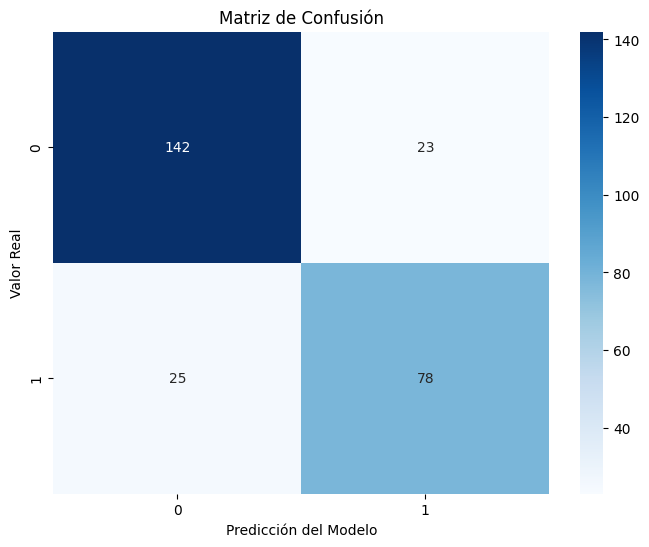

In [34]:
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

matriz_confusion = tf.math.confusion_matrix(labels=y_test, predictions=y_predict)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()